# ¿Qué riesgo asume un plan determinista si cambia la geología?

**Pregunta:** ¿Cómo puntúa un plan optimizado sobre un único modelo de valores frente a realizaciones correlacionadas espacialmente?

**Level:** 1 · Fundamentos

**Prerequisites:** Ninguno; puede comenzar aquí.

**Reading time:** 16 minutes

## Objetivos

Este notebook separa la construcción de un plan determinista, la generación de valores inciertos por bloque y la puntuación de un plan fijo. Construirá un caso CPIT pequeño con PhaseFlow, lo resolverá con OreBlocks, perturbará valores mediante un campo espacial y calculará la distribución de la misma asignación temporal. La dispersión describe el riesgo condicionado por un generador explícitamente sintético. No es un resultado de optimización estocástica, una simulación condicional ni un intervalo de confianza para un yacimiento real. Explique por qué el pronóstico del modelo medio puede diferir del promedio recalculado y nombre los supuestos responsables. El caso de 48 bloques permite inspeccionar cada etapa; no representa la escala ni la economía de una mina.

## Preparación

Desde la raíz del repositorio, instale una vez el entorno fijado con `python -m pip install -r notebooks/requirements.txt`. Este notebook no instala paquetes; la celda de imports informa las versiones activas. `oreblocks==0.6.3`.

```bash
python -m pip install -r notebooks/requirements.txt
```

In [1]:
# Importe la canalizacion documentada y reporte las versiones activas.
import importlib.metadata as metadata
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.3
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Datos

La canalización didáctica de PhaseFlow, con licencia MIT, construye una veta sintética declarada: dimensiones 4×4×3, semilla 31, cuatro períodos y descuento de 8 %. Genera valores, coeficientes de recursos, coordenadas y precedencias. No se modifican valores MineLib. OreBlocks 0.6.3 aporta métodos de planificación e incertidumbre. El conjunto es un generador de estrés lognormal, correlacionado espacialmente y con semilla; no es geología observada ni una simulación condicional. Las 24 realizaciones equiprobables se reproducen abajo. Mantenga esta procedencia en cada interpretación: las realizaciones sintéticas muestran comportamiento bajo supuestos declarados, no su probabilidad en una operación real.

## Método

Para una asignación temporal fija τ y una realización r, el valor descontado es V(τ,r) = Σ[b:τ_b≥0] (1+ρ)^(-τ_b) v_(b,r). El plan permanece fijo mientras cambian los valores. Es una nueva puntuación exacta del plan bajo esos valores; no demuestra que siga siendo óptimo. Primero construimos y validamos la entrada; después calculamos un plan determinista de referencia. Luego suavizamos un campo aleatorio blanco entre bloques vecinos y lo aplicamos multiplicativamente en espacio logarítmico. Finalmente `evaluate_across` puntúa la misma asignación en cada realización. Tonelaje y capacidad no cambian, así que se aísla la exposición del valor. No reoptimizamos: esto no es un programa estocástico.

### Paso 1: construya la entrada declarada

La declaración expone dimensiones, semilla, horizonte, tasa de descuento y fracciones de recursos. `build_instance` es la entrada identificada de la canalización de PhaseFlow; su informe indica si el objeto cumple el contrato de instancia. La geometría pequeña permite inspeccionar cada dato y mantiene breve la ejecución. Sus valores monetarios son resultados didácticos, no un caso de negocio. Cambiar la semilla crea otro yacimiento sintético; cambiar el escenario modifica la pregunta de planificación. Mantenga separadas ambas decisiones al adaptar el ejemplo.

In [2]:
# Declare un caso reproducible y construya la instancia validada.
case = Case(
    id='uncertainty-vein-4x4x3', category='teaching',
    title_en='Small synthetic vein', title_es='Veta sintetica pequena',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(
        periods=4, discount_rate=0.08, capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing'),
    ),
)
instance = build_instance(case)
print('contrato valido:', instance.report.ok, '| bloques:', instance.n_blocks)

contrato valido: True | bloques: 48


### Paso 2: resuelva la referencia determinista

El método Expected asigna bloques con los valores base generados y las restricciones de recursos y precedencias. Conserve el resultado completo: su asignación temporal es el objeto cuya exposición medimos. El pronóstico y la cota pertenecen a esta instancia CPIT determinista. Ninguno acota un conjunto aleatorio salvo que el modelo y su prueba incluyan explícitamente esas realizaciones. Así evitamos presentar un certificado determinista como garantía de riesgo.

In [3]:
# Resuelva una vez los valores base y conserve los periodos asignados.
schedule, _ = ob.solve_cpit(instance.cpit, instance.precedence, method='expected', local_search=False)
print(schedule.method, '| VPN:', round(schedule.npv, 2), '| bloques:', schedule.mined_blocks)

toposort:expected[r1] | VPN: 179191.57 | bloques: 16


### Paso 3: genere valores correlacionados

`perturb_values` crea 24 realizaciones con semilla fija, sigma 0.25 y correlación de dos bloques. El suavizado importa porque errores independientes pueden cancelarse en un pushback y reducir la variación. La implementación recentra y reescala cada campo antes de aplicar una transformación multiplicativa corregida por la media. Este modelo de estrés transparente no es un variograma ajustado. Solo cambia valores; tonelaje, capacidad, descuento y plan siguen iguales. Para un estudio real, reemplace esta etapa con simulaciones condicionales documentadas y conserve su procedencia y pesos.

In [4]:
# Genere valores correlacionados sin cambiar tonelaje ni capacidad.
ensemble = ob.perturb_values(
    instance.cpit.value, instance.x, instance.y, instance.level,
    n=24, sigma=0.25, correlation_blocks=2.0, seed=19,
)
print('realizaciones:', ensemble.n_realisations, '| sigma:', ensemble.sigma)
print('Aviso: conjunto sintetico correlacionado; no es una simulacion condicional')

realizaciones: 24 | sigma: 0.25
Aviso: conjunto sintetico correlacionado; no es una simulacion condicional


### Paso 4: puntúe la decisión fija

`evaluate_across` descuenta cada bloque extraído en su período y calcula un NPV por realización. El resultado expone media, percentil inferior P10, percentil superior P90 y optimismo determinista: pronóstico del modelo base menos media del conjunto. Un optimismo positivo indica que el pronóstico único supera el promedio de este experimento; también puede ser negativo. Omitimos deliberadamente óptimos por realización, por lo que no calculamos valor de información perfecta. Repuntuar planes candidatos no equivale a hallar el mejor plan tras conocer la geología.

In [5]:
# Recalcule el plan sin cambios en cada realizacion.
risk = ob.evaluate_across(
    instance.cpit, ensemble, {schedule.method: schedule.period_of_block},
)
print('media:', round(float(risk.expected[0]), 2))
print('P10:', round(float(risk.p10[0]), 2), '| P90:', round(float(risk.p90[0]), 2))

media: 173035.23
P10: 129694.82 | P90: 226632.3


## Resultados

**Respuesta:** En 24 realizaciones sintéticas, el plan Expected fijo promedia 173035.23 unidades de valor (P10 129694.82, P90 226632.30). El pronóstico del modelo base es 179191.57, con optimismo de 6156.34 frente a la media del conjunto. Son resultados de estrés, no probabilidades calibradas del yacimiento.

In [6]:
# Muestre las cantidades exactas usadas en la respuesta.
print(f'media={risk.expected[0]:.2f}; P10={risk.p10[0]:.2f}; P90={risk.p90[0]:.2f}')
print(f'base={risk.mean_model_npv[0]:.2f}; optimismo={risk.deterministic_optimism[0]:.2f}')

media=173035.23; P10=129694.82; P90=226632.30
base=179191.57; optimismo=6156.34


Grafique las puntuaciones calculadas y compárelas con el pronóstico determinista. Las unidades de valor provienen de esta instancia generada.

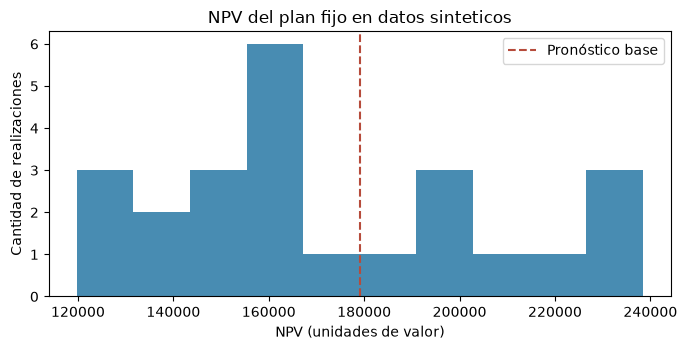

In [7]:
# Grafique las puntuaciones por escenario y marque el pronostico base.
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(risk.matrix[0], bins=10, color='#2878a5', alpha=0.85)
ax.axvline(risk.mean_model_npv[0], color='#b64b3b', linestyle='--', label='Pronóstico base')
ax.set(
    title='NPV del plan fijo en datos sinteticos',
    xlabel='NPV (unidades de valor)', ylabel='Cantidad de realizaciones',
)
ax.legend()
fig.tight_layout()
plt.show()

### Figura 1

El histograma muestra el NPV del plan fijo bajo cada realización sintética equiprobable. La línea discontinua es la puntuación del modelo base sin perturbar. Sus posiciones relativas revelan el optimismo del pronóstico para esta semilla y generador. Las colas son frecuencias de un experimento diseñado, no probabilidades calibradas para una mina. Un histograma estrecho no probaría bajo riesgo geológico: el caso solo tiene 48 bloques y el núcleo abarca dos. El gráfico usa las mismas puntuaciones resumidas en la salida, por lo que se contrasta con la media y P10 calculados.

## Resumen

Construyó un plan determinista y midió su exposición en un conjunto sintético reproducible y correlacionado espacialmente. El análisis enseña escenarios al separar la elección del plan de su nueva puntuación. Para uso operacional, sustituya el generador por simulaciones condicionales documentadas, conserve sus pesos, incluya factores inciertos relevantes y compare varios planes. Para afirmar valor de adaptación, resuelva cada realización o use un modelo estocástico. Esta salida es un experimento sobre un gemelo pequeño, no un pronóstico para MineLib ni para una operación productiva.

## Referencias

- PhaseFlow synthetic instance contract and builder: `data-pipeline/pipeline/io/schema.py`, `data-pipeline/pipeline/model/instances.py` (MIT).
- OreBlocks 0.6.3: `oreblocks.perturb_values` and `oreblocks.evaluate_across`.
- Blom, Pearce & Cote: https://arxiv.org/abs/2403.18213.
- Ramazan & Dimitrakopoulos: https://doi.org/10.1007/s11081-012-9186-2.
- Meagher, Dimitrakopoulos & Avis: https://doi.org/10.1134/S1062739114030132.